# RadZero on NIH ChestX-ray14 dataset

In [1]:
# Install the inference dependencies
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys
import time

RUN_START = time.perf_counter()
required = {'transformers': '4.39.3', 'timm': '0.9.16', 'accelerate': '0.27.2', 'peft': '0.9.0'}
packages = []
for name, version in required.items():
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        packages.append(f'{name}=={version}')
if importlib.util.find_spec('cv2') is None:
    packages.append('opencv-python-headless==4.11.0.86')
if importlib.util.find_spec('pydicom') is None:
    packages.append('pydicom==2.4.4')
try:
    hub_major = int(metadata.version('huggingface-hub').split('.')[0])
except metadata.PackageNotFoundError:
    hub_major = 1
if hub_major >= 1:
    packages.append('huggingface-hub==0.36.2')
if packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *packages])
print('Inference dependencies ready.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.0/280.0 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.9/190.9 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 79.9 MB/s eta 0:00:00
Inference dependencies ready.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.85.7 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.15.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.39.3 which is incompatible.


In [2]:
# Import the evaluation libraries
import hashlib
import importlib.util
import json
import os
import random
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image
from sklearn.metrics import (
    accuracy_score, auc, confusion_matrix, precision_recall_curve,
    precision_recall_fscore_support, roc_curve,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

In [3]:
# Configure the official model and Kaggle evaluation
MODEL_ID = 'Deepnoid/RadZero'
MODEL_REVISION = '1e6e7d6295a13aa0a4a7e1c1e2bb36b9ef4e02e8'
REPO_COMMIT = '656ae5f1af3f106e96c95542ce3ee5c0ee8777fc'
SEED = 42
INFERENCE_BATCH_SIZE = 8
NUM_WORKERS = 4
LOG_EVERY = 100
THRESHOLD = 0.5
TASK_EPOCHS = 0
NIH_ROOT = None
INPUT_ROOT = Path('/kaggle/input')
RESULTS = Path('/kaggle/working/radzero_nih_chestxray14')
CACHE_ROOT = Path('/tmp/radzero_cache')
LABELS = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule',
          'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema',
          'Fibrosis', 'Pleural Thickening', 'Hernia']
DISPLAY_LABELS = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Pneumothorax', 'Hernia']

RESULTS.mkdir(parents=True, exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'source').mkdir(exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ['HF_HOME'] = str(CACHE_ROOT)
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle session options, then start a fresh session.')
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
print('Using:', ', '.join(torch.cuda.get_device_name(i) for i in range(2)))
print('Protocol: zero-shot evaluation | NIH training epochs:', TASK_EPOCHS)

Using: Tesla T4, Tesla T4
Protocol: zero-shot evaluation | NIH training epochs: 0


In [4]:
# Download the pinned official model and evaluation files
from huggingface_hub import snapshot_download
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

download_start = time.perf_counter()
MODEL_DIR = Path(snapshot_download(
    MODEL_ID,
    revision=MODEL_REVISION,
    allow_patterns=['*.py', 'config.json', 'preprocessor_config.json', 'tokenizer.json',
                    'tokenizer_config.json', 'special_tokens_map.json', 'vocab.txt',
                    'model.safetensors', 'README.md', 'requirements.txt', 'data/ChestXray14/*'],
    max_workers=2,
))
download_seconds = time.perf_counter() - download_start
BENCHMARK = MODEL_DIR / 'data/ChestXray14'
print(f'Official release ready in {download_seconds / 60:.1f} minutes.')

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

align_transformers.py: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

common_layers.py:   0%|          | 0.00/935 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

utils.py: 0.00B [00:00, ?B/s]

vision_encoders.py:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Official release ready in 0.1 minutes.


In [5]:
# Verify the released checkpoint
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

checkpoint = MODEL_DIR / 'model.safetensors'
checkpoint_hash = sha256_file(checkpoint)
if checkpoint_hash != '7f8edcce8dbc42db753b0b110ab7eb7d5814825733b796f930973c46ee95c622':
    raise ValueError('The downloaded checkpoint does not match the official release.')
print('Checkpoint checksum verified.')

Checkpoint checksum verified.


In [6]:
# Read the authors' NIH benchmark labels and prompts
data_start = time.perf_counter()
manifest = pd.read_csv(BENCHMARK / 'chestxray14_test_image.csv')
label_table = pd.read_csv(BENCHMARK / 'test_list.txt', sep=r'\s+', header=None, names=['label_path', *LABELS])
prompt_json = json.loads((BENCHMARK / 'chestxray14_test_text.json').read_text())
PROMPTS = [prompt_json[str(i)][0] for i in range(len(LABELS))]

def image_key(path):
    return Path(str(path).replace('\\', '/')).name

manifest['image_id'] = manifest['Path'].map(image_key)
label_table['image_id'] = label_table['label_path'].map(image_key)
if len(manifest) != 22433 or manifest['image_id'].duplicated().any():
    raise ValueError('Expected 22,433 unique images in the RadZero NIH benchmark manifest.')
frame = manifest.merge(label_table[['image_id', *LABELS]], on='image_id', how='left', validate='one_to_one')
if not frame[LABELS].isin([0, 1]).all().all():
    raise ValueError('Every benchmark image must have fourteen binary labels.')
frame[LABELS] = frame[LABELS].astype(int)
frame['patient_id'] = frame['image_id'].str.split('_').str[0]
print(f"Test: {len(frame):,} images | {frame['patient_id'].nunique():,} patients")
print('Positive images:', frame[LABELS].sum().to_dict())

Test: 22,433 images | 6,187 patients
Positive images: {'Atelectasis': 2420, 'Cardiomegaly': 582, 'Effusion': 2754, 'Infiltration': 3938, 'Mass': 1133, 'Nodule': 1335, 'Pneumonia': 242, 'Pneumothorax': 1089, 'Consolidation': 957, 'Edema': 413, 'Emphysema': 509, 'Fibrosis': 362, 'Pleural Thickening': 734, 'Hernia': 42}


In [7]:
# Find the original NIH PNG images in the attached dataset
if NIH_ROOT is None:
    metadata_files = list(INPUT_ROOT.rglob('Data_Entry_2017.csv'))
    if len(metadata_files) != 1:
        raise FileNotFoundError('Attach one complete NIH Chest X-rays dataset, or set NIH_ROOT to its image root.')
    data_root = metadata_files[0].parent
    anchor_name = frame.loc[0, 'image_id']
    if not next(data_root.rglob(anchor_name), None) and data_root.parent != INPUT_ROOT:
        data_root = data_root.parent
else:
    data_root = Path(NIH_ROOT)

wanted_names = set(frame['image_id'])
image_paths = {}
duplicates = []
for path in data_root.rglob('*.png'):
    if path.name in wanted_names:
        if path.name in image_paths:
            duplicates.append(path.name)
        image_paths[path.name] = path
if duplicates:
    raise ValueError(f'Duplicate NIH image names found. Select one dataset copy with NIH_ROOT. Example: {duplicates[0]}')
missing = sorted(wanted_names - image_paths.keys())
if missing:
    raise FileNotFoundError(f'{len(missing):,} benchmark images are missing. First: {missing[0]}. Attach all NIH PNG folders or correct NIH_ROOT.')
frame['image_path'] = frame['image_id'].map(image_paths)
data_seconds = time.perf_counter() - data_start
print('NIH image root:', data_root)
print(f'All {len(frame):,} benchmark images found in the authors\' manifest order.')

NIH image root: /kaggle/input/datasets/nih-chest-xrays/data
All 22,433 benchmark images found in the authors' manifest order.


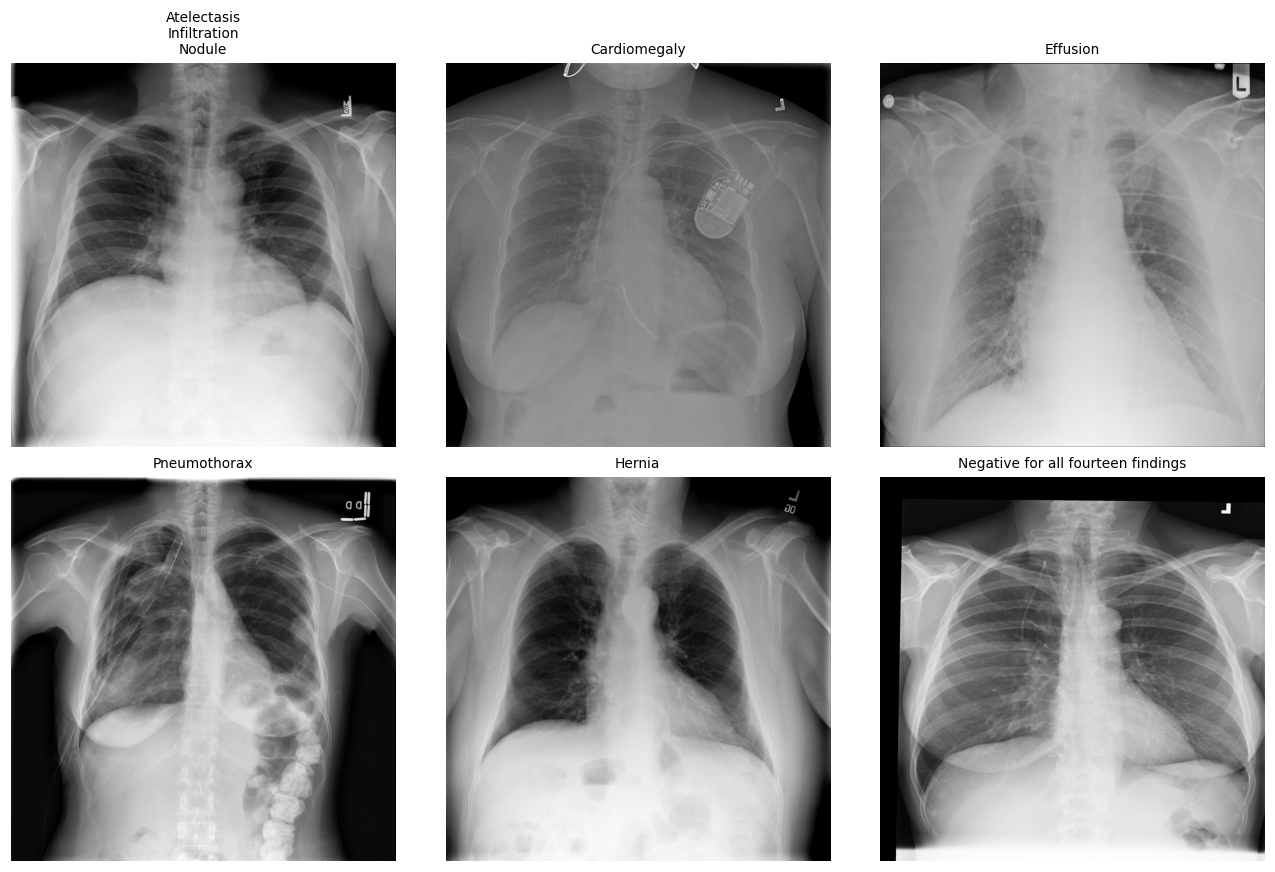

In [8]:
# Show positive examples and an image negative for all findings
sample_indices = []
for label in DISPLAY_LABELS:
    candidates = frame[(frame[label] == 1) & ~frame.index.isin(sample_indices)]
    sample_indices.append(int(candidates.sample(1, random_state=SEED).index[0]))
negative_rows = frame[frame[LABELS].sum(axis=1) == 0]
if len(negative_rows):
    sample_indices.append(int(negative_rows.sample(1, random_state=SEED).index[0]))

figure_start = time.perf_counter()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, index in zip(axes.flat, sample_indices):
    row = frame.loc[index]
    with Image.open(row['image_path']) as image:
        ax.imshow(image, cmap='gray')
    findings = [label for label in LABELS if row[label] == 1]
    ax.set_title('\n'.join(findings) if findings else 'Negative for all fourteen findings', fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(sample_indices):]:
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'figures/sample_images.png', dpi=180)
plt.show()
plt.close(fig)
figure_seconds = time.perf_counter() - figure_start

In [9]:
# Load the official processor and tokenizer
image_processor = AutoImageProcessor.from_pretrained(str(MODEL_DIR))
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR))
if image_processor.size != {'height': 518, 'width': 518}:
    raise ValueError('The released high-resolution processor must use 518 x 518 images.')
tokenized_prompts = tokenizer(PROMPTS, padding=True, truncation=True, return_tensors='pt')
print('Released processor: 518 x 518 | prompts:', len(PROMPTS))

Released processor: 518 x 518 | prompts: 14


In [10]:
# Load every trained RadZero component in FP32
model_start = time.perf_counter()
model, loading_info = AutoModel.from_pretrained(
    str(MODEL_DIR),
    trust_remote_code=True,
    torch_dtype=torch.float32,
    output_loading_info=True,
)
loading_errors = {
    key: loading_info.get(key) for key in ['missing_keys', 'unexpected_keys', 'mismatched_keys', 'error_msgs']
    if loading_info.get(key)
}
if loading_errors:
    raise RuntimeError(f'The checkpoint did not load completely: {loading_errors}')
model.eval().requires_grad_(False)
model = model.to('cuda:0')
model_seconds = time.perf_counter() - model_start
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f'Complete model loaded: {parameter_count:,} parameters | {model_seconds / 60:.1f} minutes')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Complete model loaded: 209,392,513 parameters | 0.2 minutes


In [11]:
# Apply the official benchmark image normalization
class NIHImages(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            pixels = np.array(image)
        normalized = cv2.normalize(pixels, None, 0, 255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
        return Image.fromarray(normalized)

def collate_images(images):
    processed = image_processor(images)
    return torch.FloatTensor(np.array(processed['pixel_values']))

test_dataset = NIHImages(frame['image_path'])
test_loader = DataLoader(
    test_dataset, batch_size=INFERENCE_BATCH_SIZE, shuffle=False, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=True, collate_fn=collate_images,
    persistent_workers=NUM_WORKERS > 0,
)

In [12]:
# Run the official scoring method on both T4 GPUs
class RadZeroClassifier(nn.Module):
    def __init__(self, official_model, prompts):
        super().__init__()
        self.model = official_model
        self.register_buffer('prompt_ids', prompts['input_ids'], persistent=False)
        self.register_buffer('prompt_mask', prompts['attention_mask'], persistent=False)

    @torch.no_grad()
    def forward(self, pixel_values):
        prompts = {'input_ids': self.prompt_ids, 'attention_mask': self.prompt_mask}
        output = self.model.compute_logits(pixel_values, [prompts])
        return output['logits'].reshape(pixel_values.shape[0], len(LABELS))

classifier = RadZeroClassifier(model, tokenized_prompts).to('cuda:0').eval()
parallel_model = nn.DataParallel(classifier, device_ids=[0, 1]).eval()

In [13]:
# Check singleton and two-GPU scores before evaluation
check_start = time.perf_counter()
check_pixels = collate_images([test_dataset[i] for i in range(4)]).to('cuda:0')
with torch.no_grad():
    direct_scores = classifier(check_pixels)
    parallel_scores = parallel_model(check_pixels)
    singleton_scores = classifier(check_pixels[:1])
if not torch.isfinite(parallel_scores).all():
    raise ValueError('Non-finite model scores were detected.')
if not torch.allclose(direct_scores, parallel_scores, atol=1e-4, rtol=1e-4):
    raise ValueError('Single-GPU and two-GPU scores disagree beyond the stated FP32 tolerance.')
if not torch.allclose(direct_scores[:1], singleton_scores, atol=1e-4, rtol=1e-4):
    raise ValueError('Singleton and batched scores disagree beyond the stated FP32 tolerance.')
parity = {
    'two_gpu_max_absolute_difference': float((direct_scores - parallel_scores).abs().max()),
    'singleton_max_absolute_difference': float((direct_scores[:1] - singleton_scores).abs().max()),
    'atol': 1e-4, 'rtol': 1e-4,
}
for device in range(2):
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)
check_seconds = time.perf_counter() - check_start
del check_pixels, direct_scores, parallel_scores, singleton_scores
print('Score checks passed:', parity)

Score checks passed: {'two_gpu_max_absolute_difference': 1.5020370483398438e-05, 'singleton_max_absolute_difference': 9.894371032714844e-06, 'atol': 0.0001, 'rtol': 0.0001}


/tmp/radzero_cache/modules/transformers_modules/1e6e7d6295a13aa0a4a7e1c1e2bb36b9ef4e02e8/losses.py:210: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4480.)
  logits = logits.T


In [14]:
# Evaluate every image in the released NIH benchmark
inference_start = time.perf_counter()
score_batches = []
processed_images = 0
with torch.no_grad():
    for batch_index, pixels in enumerate(test_loader, start=1):
        scores = parallel_model(pixels.to('cuda:0', non_blocking=True))
        score_batches.append(scores.float().cpu().numpy())
        processed_images += len(pixels)
        if batch_index == 1 or batch_index % LOG_EVERY == 0 or batch_index == len(test_loader):
            elapsed = time.perf_counter() - inference_start
            speed = processed_images / max(elapsed, 1e-9)
            remaining = (len(frame) - processed_images) / max(speed, 1e-9)
            print(f'{processed_images:5d}/{len(frame)} images | {speed:.1f} images/s | remaining {remaining / 60:.1f} min', flush=True)
for device in range(2):
    torch.cuda.synchronize(device)
inference_seconds = time.perf_counter() - inference_start
raw_scores = np.concatenate(score_batches, axis=0)
truth = frame[LABELS].to_numpy(dtype=np.int64)
if raw_scores.shape != truth.shape or not np.isfinite(raw_scores).all():
    raise ValueError('Expected a finite 22,433 x 14 score matrix in the original manifest order.')
probabilities = torch.from_numpy(raw_scores).sigmoid().numpy()
peak_memory_gb = [torch.cuda.max_memory_allocated(i) / 1024 ** 3 for i in range(2)]
print(f'Evaluation finished in {inference_seconds / 60:.1f} minutes.')

    8/22433 images | 4.2 images/s | remaining 89.9 min
  800/22433 images | 9.7 images/s | remaining 37.3 min
 1600/22433 images | 9.5 images/s | remaining 36.7 min
 2400/22433 images | 9.3 images/s | remaining 35.9 min
 3200/22433 images | 9.2 images/s | remaining 34.7 min
 4000/22433 images | 9.2 images/s | remaining 33.4 min
 4800/22433 images | 9.2 images/s | remaining 32.0 min
 5600/22433 images | 9.1 images/s | remaining 30.7 min
 6400/22433 images | 9.1 images/s | remaining 29.3 min
 7200/22433 images | 9.1 images/s | remaining 27.8 min
 8000/22433 images | 9.1 images/s | remaining 26.4 min
 8800/22433 images | 9.1 images/s | remaining 24.9 min
 9600/22433 images | 9.1 images/s | remaining 23.5 min
10400/22433 images | 9.1 images/s | remaining 22.0 min
11200/22433 images | 9.1 images/s | remaining 20.6 min
12000/22433 images | 9.1 images/s | remaining 19.1 min
12800/22433 images | 9.1 images/s | remaining 17.7 min
13600/22433 images | 9.1 images/s | remaining 16.2 min
14400/2243

In [15]:
# Save image-level predictions before plotting
predictions = frame[['image_id', 'patient_id']].copy()
for column, label in enumerate(LABELS):
    predictions[f'{label}_label'] = truth[:, column]
    predictions[f'{label}_logit'] = raw_scores[:, column]
    predictions[f'{label}_sigmoid'] = probabilities[:, column]
predictions.to_csv(RESULTS / 'predictions.csv', index=False)

In [16]:
# Load the authors' unchanged metric functions
metric_url = f'https://raw.githubusercontent.com/deepnoid-ai/RadZero/{REPO_COMMIT}/external/CARZero/utils.py'
response = requests.get(metric_url, timeout=60)
response.raise_for_status()
metric_path = RESULTS / 'source/official_metric_utils.py'
metric_path.write_bytes(response.content)
if sha256_file(metric_path) != '141d4bcc31eb1248da28ccbab8851fa1806cdcb70dafbbd03ad55a1acb6f2e1c':
    raise ValueError('The metric source does not match the pinned official code.')
spec = importlib.util.spec_from_file_location('radzero_official_metrics', metric_path)
official_metrics = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official_metrics)

In [17]:
# Calculate the official ranking metrics and fixed-threshold metrics
metric_start = time.perf_counter()
macro_auc, micro_auc, weighted_auc, per_class_auc = official_metrics.eval_auc(raw_scores, truth)
micro_auprc, macro_auprc = official_metrics.calculate_micro_macro_auprc(truth, raw_scores)
predicted = (probabilities >= THRESHOLD).astype(int)
precision, recall, f1, support = precision_recall_fscore_support(truth, predicted, average=None, zero_division=0)
pr_areas = []
for column in range(len(LABELS)):
    p, r, _ = precision_recall_curve(truth[:, column], raw_scores[:, column])
    pr_areas.append(auc(r, p))
metrics_df = pd.DataFrame({
    'AUROC': per_class_auc, 'AUPRC': pr_areas,
    'accuracy': (predicted == truth).mean(axis=0),
    'precision': precision, 'recall': recall, 'F1': f1,
    'positives': support.astype(int), 'threshold': THRESHOLD,
}, index=LABELS)
metrics_df.index.name = 'finding'
summary = {
    'macro_AUROC': float(macro_auc), 'micro_AUROC': float(micro_auc),
    'weighted_AUROC': float(weighted_auc), 'macro_AUPRC': float(macro_auprc),
    'micro_AUPRC': float(micro_auprc), 'labelwise_accuracy': float((predicted == truth).mean()),
    'subset_accuracy': float(accuracy_score(truth, predicted)),
    'macro_precision': float(precision.mean()), 'macro_recall': float(recall.mean()),
    'macro_F1': float(f1.mean()), 'fixed_sigmoid_threshold': THRESHOLD,
    'paper_macro_AUROC': 0.804, 'difference_from_rounded_paper': float(macro_auc - 0.804),
}
metric_seconds = time.perf_counter() - metric_start
print(metrics_df.round(3).to_string())
print(f'\nMacro AUROC: {macro_auc:.3f} | paper reference: 0.804')
print('Accuracy, precision, recall and F1 use a fixed sigmoid threshold; it is not calibrated on these test labels.')

                    AUROC  AUPRC  accuracy  precision  recall     F1  positives  threshold
finding                                                                                   
Atelectasis         0.792  0.277     0.651      0.211   0.814  0.335       2420        0.5
Cardiomegaly        0.863  0.202     0.728      0.075   0.835  0.138        582        0.5
Effusion            0.854  0.418     0.722      0.289   0.866  0.434       2754        0.5
Infiltration        0.669  0.330     0.733      0.326   0.489  0.391       3938        0.5
Mass                0.837  0.296     0.752      0.142   0.774  0.239       1133        0.5
Nodule              0.727  0.177     0.332      0.075   0.904  0.139       1335        0.5
Pneumonia           0.766  0.048     0.619      0.021   0.769  0.042        242        0.5
Pneumothorax        0.875  0.315     0.527      0.088   0.934  0.161       1089        0.5
Consolidation       0.784  0.113     0.705      0.102   0.752  0.179        957        0.5

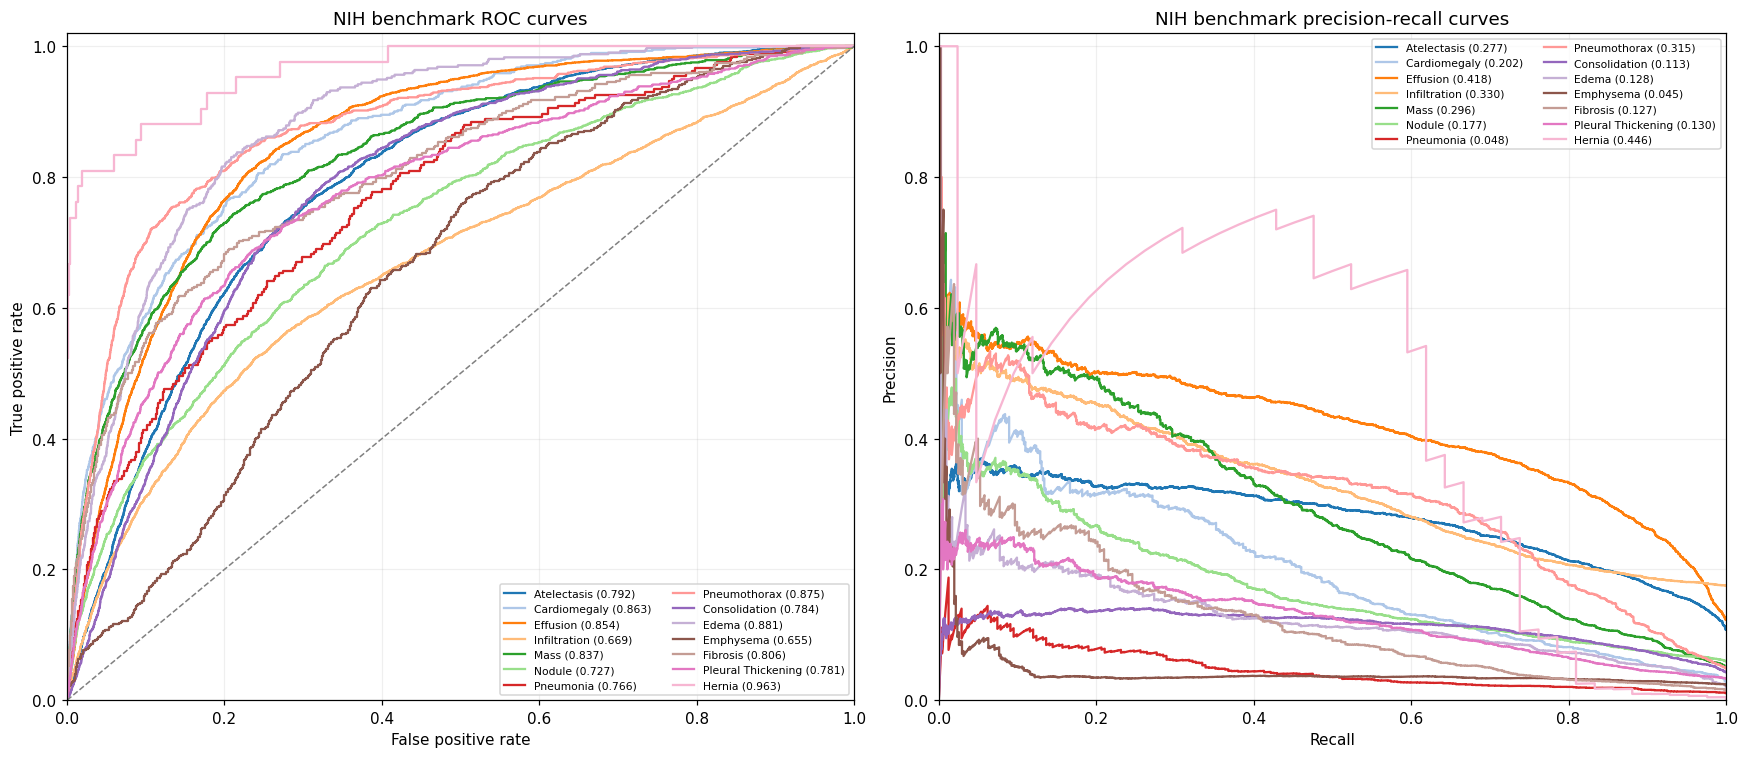

In [18]:
# Plot the test ROC and precision-recall curves
plot_start = time.perf_counter()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = plt.get_cmap('tab20').colors
for column, label in enumerate(LABELS):
    false_positive, true_positive, _ = roc_curve(truth[:, column], raw_scores[:, column])
    p, r, _ = precision_recall_curve(truth[:, column], raw_scores[:, column])
    axes[0].plot(false_positive, true_positive, color=colors[column], label=f'{label} ({per_class_auc[column]:.3f})')
    axes[1].plot(r, p, color=colors[column], label=f'{label} ({pr_areas[column]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(title='NIH benchmark ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='NIH benchmark precision-recall curves', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(RESULTS / 'figures/roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)
figure_seconds += time.perf_counter() - plot_start

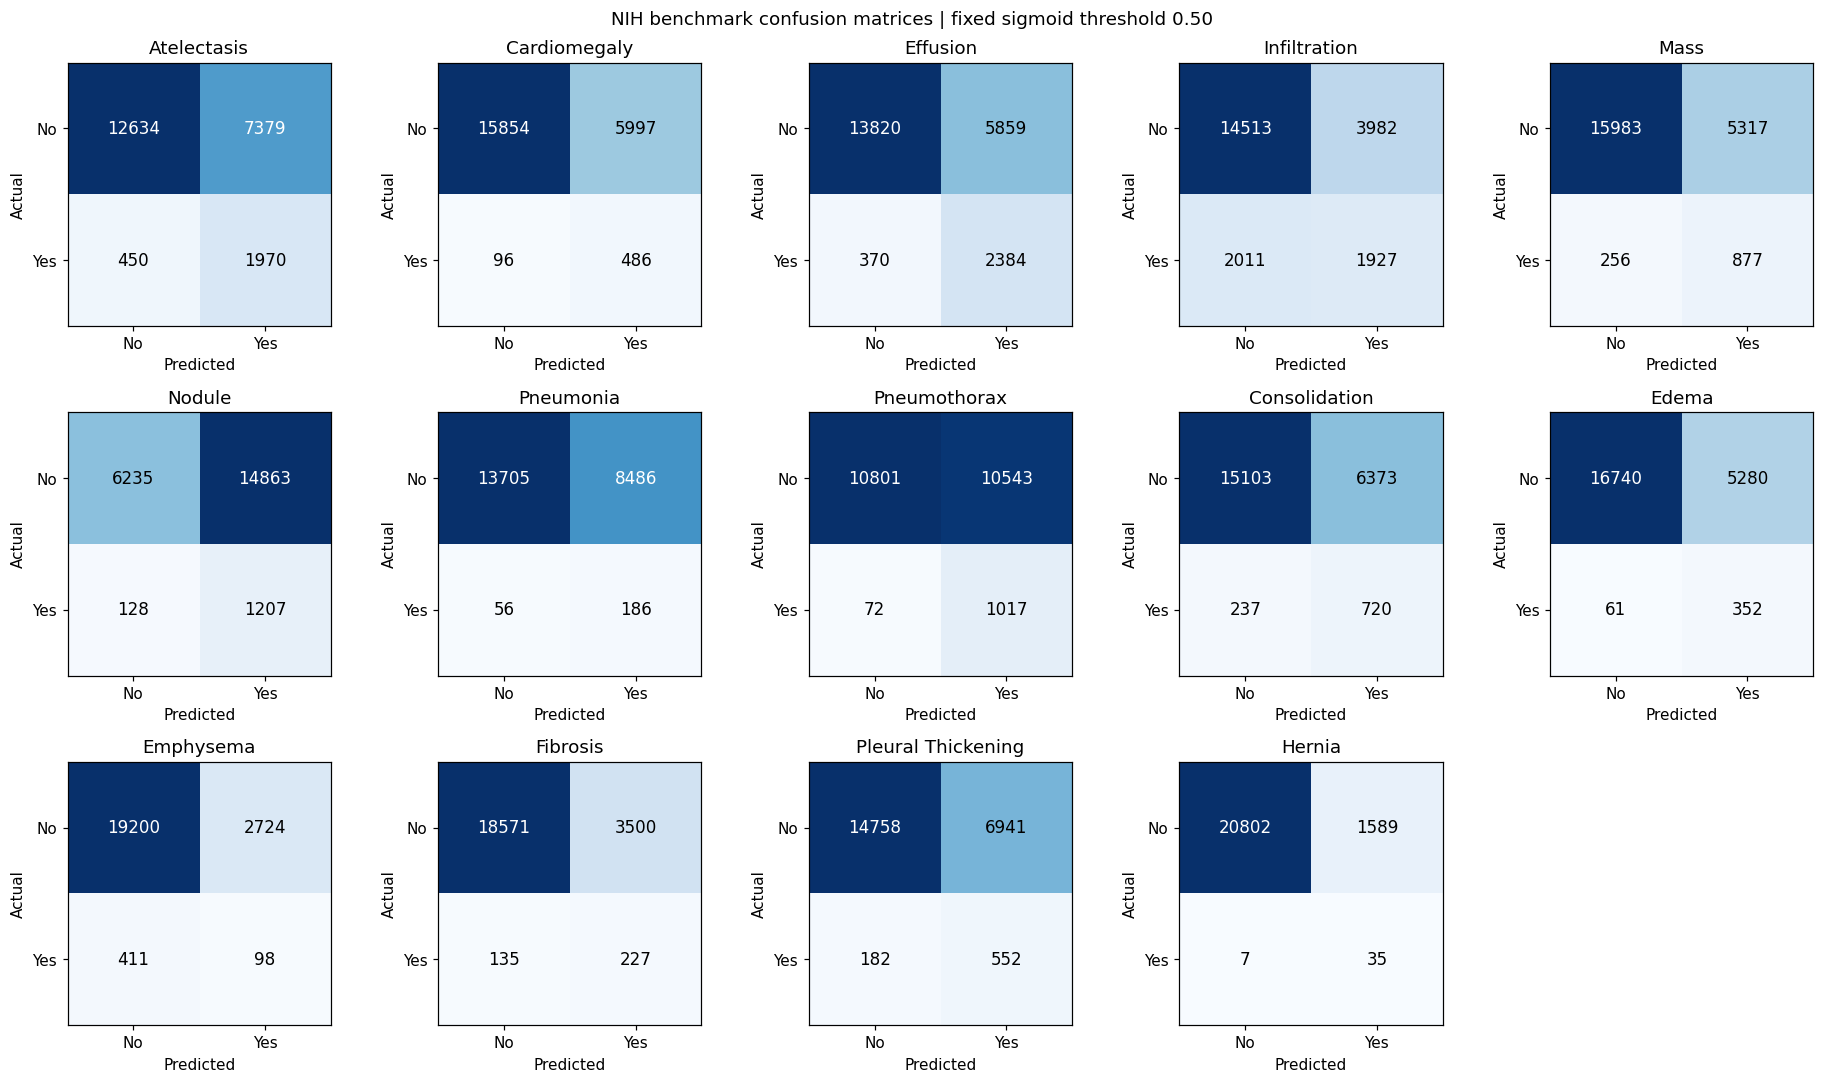

In [19]:
# Plot the fourteen independent confusion matrices
plot_start = time.perf_counter()
fig, axes = plt.subplots(3, 5, figsize=(17, 10))
for column, label in enumerate(LABELS):
    ax = axes.flat[column]
    matrix = confusion_matrix(truth[:, column], predicted[:, column], labels=[0, 1])
    ax.imshow(matrix, cmap='Blues', vmin=0)
    for row in range(2):
        for col in range(2):
            color = 'white' if matrix[row, col] > matrix.max() / 2 else 'black'
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center', color=color, fontsize=11)
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1])
    ax.set_xticklabels(['No', 'Yes'])
    ax.set_yticklabels(['No', 'Yes'])
axes.flat[-1].axis('off')
fig.suptitle(f'NIH benchmark confusion matrices | fixed sigmoid threshold {THRESHOLD:.2f}')
fig.tight_layout()
fig.savefig(RESULTS / 'figures/confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)
figure_seconds += time.perf_counter() - plot_start

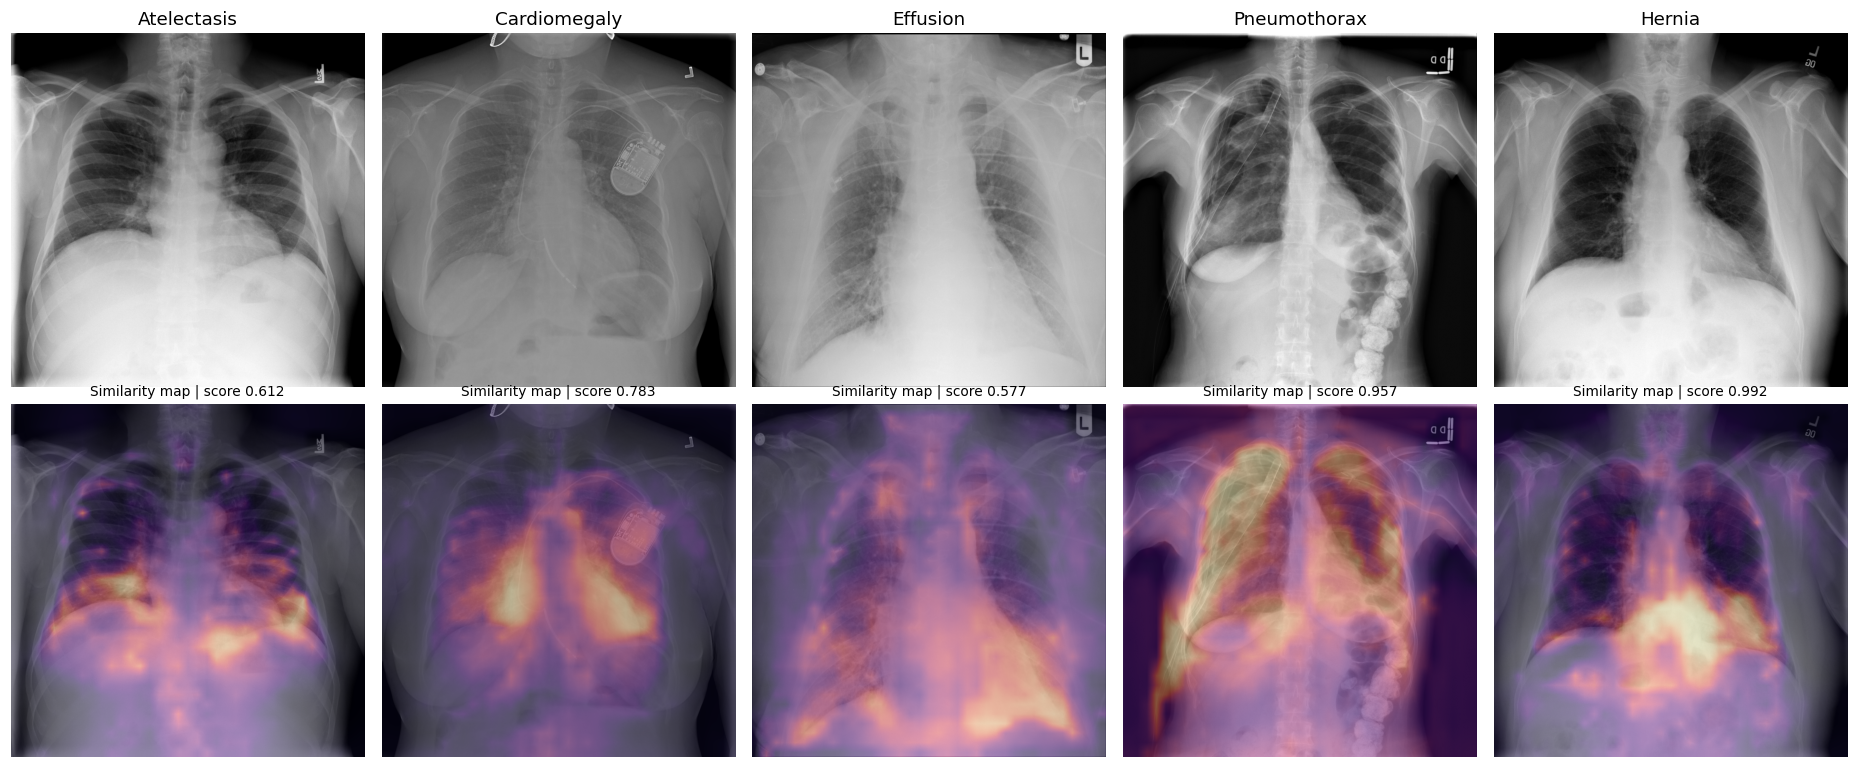

In [20]:
# Show the official RadZero similarity maps for positive examples
plot_start = time.perf_counter()
spec = importlib.util.spec_from_file_location('radzero_official_visuals', MODEL_DIR / 'utils.py')
official_visuals = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official_visuals)
device_prompts = {key: value.to('cuda:0') for key, value in tokenized_prompts.items()}
fig, axes = plt.subplots(2, len(DISPLAY_LABELS), figsize=(17, 7))
with torch.no_grad():
    for display_column, (label, index) in enumerate(zip(DISPLAY_LABELS, sample_indices[:len(DISPLAY_LABELS)])):
        column = LABELS.index(label)
        image = test_dataset[index]
        pixels = collate_images([image]).to('cuda:0')
        output = model.compute_logits(pixels, [device_prompts])
        patch_scores = output['similarity_scores'][0, column]
        similarity_map = official_visuals.interpolate_similarity_scores(
            patch_scores, (image.height, image.width), image_processor,
        ).sigmoid()[0].cpu().numpy()
        axes[0, display_column].imshow(image, cmap='gray')
        axes[1, display_column].imshow(image, cmap='gray')
        axes[1, display_column].imshow(similarity_map, cmap='magma', alpha=0.5, vmin=0, vmax=1)
        axes[0, display_column].set_title(label)
        axes[1, display_column].set_title(f'Similarity map | score {probabilities[index, column]:.3f}', fontsize=9)
        axes[0, display_column].axis('off')
        axes[1, display_column].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'figures/similarity_maps.png', dpi=160)
plt.show()
plt.close(fig)
figure_seconds += time.perf_counter() - plot_start

In [21]:
# Save the evaluation settings and official source files
source_files = ['config.json', 'preprocessor_config.json', 'modeling_radzero.py', 'configuration_radzero.py',
                'losses.py', 'align_transformers.py', 'vision_encoders.py', 'text_encoders.py',
                'common_layers.py', 'utils.py', 'inference.py', 'README.md', 'requirements.txt']
source_hashes = {}
for name in source_files:
    source = MODEL_DIR / name
    if source.exists():
        shutil.copy2(source, RESULTS / 'source' / name)
        source_hashes[name] = sha256_file(source)
for source in BENCHMARK.iterdir():
    if source.is_file():
        shutil.copy2(source, RESULTS / 'source' / source.name)
        source_hashes[source.name] = sha256_file(source)
source_hashes['official_metric_utils.py'] = sha256_file(metric_path)
config = {
    'model_id': MODEL_ID, 'model_revision': MODEL_REVISION, 'github_commit': REPO_COMMIT,
    'checkpoint_sha256': checkpoint_hash, 'parameter_count': parameter_count,
    'backbone_revisions': {
        'vision': getattr(model.vision_model.config, '_commit_hash', None),
        'text': getattr(model.text_model.config, '_commit_hash', None),
    },
    'learned_temperature_denominator': float(model.loss_fns['KeyPhraseAlignmentLoss'].loss_temperature.exp().detach().cpu()),
    'protocol': 'RadZero author-released NIH 22,433-image zero-shot classification',
    'labels': LABELS, 'prompts': PROMPTS, 'display_labels': DISPLAY_LABELS,
    'data_root': str(data_root), 'benchmark_images': len(frame), 'input_size': [518, 518],
    'benchmark_intensity_normalization': 'cv2.NORM_MINMAX, 0..255, CV_8U',
    'processor': image_processor.to_dict(), 'dtype': 'float32',
    'inference_batch_size': INFERENCE_BATCH_SIZE, 'num_workers': NUM_WORKERS,
    'seed': SEED, 'target_dataset_training_epochs': TASK_EPOCHS, 'log_every_batches': LOG_EVERY,
    'target_dataset_optimizer': None, 'target_dataset_learning_rate': None,
    'fixed_sigmoid_threshold': THRESHOLD, 'threshold_selected_on_test': False,
    'ranking_metrics_input': 'raw official logits', 'AUPRC': 'trapezoidal precision-recall area',
    'execution_changes': [f'inference batch {INFERENCE_BATCH_SIZE} instead of repository default 64',
                          'two-GPU wrapper', 'singleton output reshaped to batch x findings'],
    'original_training': {'dataset': 'MIMIC-CXR', 'max_epochs': 20, 'patience': 5,
        'optimizer': 'AdamW', 'learning_rate': 1e-4, 'weight_decay': 0.05,
        'scheduler': 'cosine', 'warmup_steps': 50, 'gradient_clip': 1.0,
        'global_batch_size': 256, 'precision': 'BF16', 'hardware': '4 x H100',
        'reported_hours': 13, 'note': 'Training behind the released weights; not run here.'},
    'score_parity_check': parity, 'source_sha256': source_hashes,
    'sources': {'paper': 'https://arxiv.org/abs/2504.07416',
                'repository': 'https://github.com/deepnoid-ai/RadZero',
                'model': 'https://huggingface.co/Deepnoid/RadZero',
                'dataset': 'https://www.kaggle.com/datasets/nih-chest-xrays/data'},
}
(RESULTS / 'config.json').write_text(json.dumps(config, indent=2, default=str))
metrics_df.to_csv(RESULTS / 'class_metrics.csv')
(RESULTS / 'summary_metrics.json').write_text(json.dumps(summary, indent=2))
frame[['image_id', 'patient_id', *LABELS]].to_csv(RESULTS / 'manifest_used.csv', index=False)

In [22]:
# Save the environment and computation time
hardware = {'torch': torch.__version__, 'cuda': torch.version.cuda,
            'gpus': [torch.cuda.get_device_name(i) for i in range(2)],
            'inference_peak_allocated_gb': peak_memory_gb}
(RESULTS / 'hardware.json').write_text(json.dumps(hardware, indent=2))
(RESULTS / 'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
timing = {
    'release_download_seconds': download_seconds, 'data_preparation_seconds': data_seconds,
    'model_loading_seconds': model_seconds, 'score_check_seconds': check_seconds,
    'target_dataset_training_seconds': 0, 'test_inference_seconds': inference_seconds,
    'test_images_per_second': len(frame) / inference_seconds,
    'metric_seconds': metric_seconds, 'figure_seconds': figure_seconds,
    'total_notebook_seconds': time.perf_counter() - RUN_START,
}
(RESULTS / 'timing.json').write_text(json.dumps(timing, indent=2))
print(f"Total notebook time: {timing['total_notebook_seconds'] / 60:.1f} minutes")
print('Results saved to:', RESULTS)

Total notebook time: 46.5 minutes
Results saved to: /kaggle/working/radzero_nih_chestxray14
